In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from adjustText import adjust_text
import sys
sys.path.insert(0, '..')
from popularity_queries import pytrends_query, wiki_pageviews

In [ ]:
#ignore i got rate limited :( START,END = "2025010100", "2026091000" 

#def score(path,name_col,label):
    #df = pd.read_csv(path)
   # df=df.dropna(subset=["page_name", name_col]).drop_duplicates("page_name").copy()

  #  df["name_only"]=df[name_col]
 #   df["name_length"]=df["name_only"].str.len()
#
    #views = wiki_pageviews(df["page_name"].tolist(), START, END)
   # df["total_views"]=df["page_name"].map(views.sum())
  #  df["body_type"] = label
 #   return df.dropna(subset=["total_views"])
#
#stars = score(r'C:\Users\mayad\OneDrive\Documents\GitHub\CelestialCelebs\data\star_data.csv', "modern_name", "star")
#exoplanets= score(r'C:\Users\mayad\OneDrive\Documents\GitHub\CelestialCelebs\data\exoplanet_list.csv', "planet_name", "exoplanet")


JSONDecodeError: Expecting value: line 1 column 1 (char 0)

In [ ]:
import time
import requests
import pandas as pd
import matplotlib.pyplot as plt
from urllib.parse import unquote
from adjustText import adjust_text
from popularity_queries import wiki_pageviews

base = r'C:\Users\mayad\OneDrive\Documents\GitHub\CelestialCelebs\data'
START, END = "2025010100", "2026091000"   # YYYYMMDDHH, 10 digits

# ---------- 1. helpers ----------
def resolve_titles(names):
    """Ask Wikipedia where each title really redirects to."""
    header = {'User-Agent': 'WikiDataScraper/1.0 (https://github.com/etu8924/CelestialCelebs)'}
    final = {}
    for i in range(0, len(names), 50):
        batch = names[i:i+50]
        r = requests.get("https://en.wikipedia.org/w/api.php",
                         params={"action": "query", "titles": "|".join(batch),
                                 "redirects": 1, "format": "json"},
                         headers=header).json()
        mapping = {}
        for item in r["query"].get("normalized", []):
            mapping[item["from"]] = item["to"]
        for item in r["query"].get("redirects", []):
            mapping[item["from"]] = item["to"]
        for name in batch:
            title = name
            while title in mapping:
                title = mapping[title]
            final[name] = title
    return final

def safe_pageviews(titles, chunk=20, retries=3):
    """Fetch views in small chunks so one bad title doesn't kill the run."""
    totals, failed = {}, []
    for i in range(0, len(titles), chunk):
        batch = titles[i:i+chunk]
        for attempt in range(retries):
            try:
                v = wiki_pageviews(batch, start_date=START, end_date=END)
                totals.update(v.sum().to_dict())
                break
            except Exception:
                if attempt == retries - 1:
                    failed.extend(batch)
                else:
                    time.sleep(2 * (attempt + 1))
        time.sleep(0.5)
    return pd.Series(totals), failed

def build(df, name_col, label, views):
    df = df.dropna(subset=["wiki_title", name_col]).drop_duplicates("wiki_title").copy()
    df["name_only"] = df[name_col]
    df["name_length"] = df["name_only"].str.len()
    df["total_views"] = df["wiki_title"].map(views)
    df["body_type"] = label
    return df.dropna(subset=["total_views"])[["name_only", "name_length", "total_views", "body_type"]]

stars_raw = pd.read_csv(rf'{base}\star_data.csv')
planets_raw = pd.read_csv(rf'{base}\exoplanet_data.csv')
print(planets_raw.columns.tolist())
stars_raw = stars_raw.dropna(subset=["page_name", "modern_name"]).copy()
stars_raw["wiki_title"] = stars_raw["page_name"]

planets_raw = planets_raw.dropna(subset=["page_name", "planet_name"]).copy()
clean = planets_raw["page_name"].apply(unquote).str.replace("_", " ")
real = resolve_titles(clean.unique().tolist())
planets_raw["wiki_title"] = clean.map(real).str.replace(" ", "_")

#find views without being rate limited
star_views, star_failed = safe_pageviews(stars_raw["wiki_title"].unique().tolist())
planet_views, planet_failed = safe_pageviews(planets_raw["wiki_title"].unique().tolist())
print(len(star_failed), "star pages failed;", len(planet_failed), "planet pages failed")

#combine into one dataset
stars = build(stars_raw, "modern_name", "star", star_views)
planets = build(planets_raw, "planet_name", "exoplanet", planet_views)
combined = pd.concat([stars, planets], ignore_index=True)
combined.to_csv(rf'{base}\stars_exoplanets_views.csv', index=False)
print(combined.groupby("body_type").size())

['planet_name', 'star_name', 'page_name', 'main_id', 'ra', 'dec']
0 star pages failed; 0 planet pages failed
body_type
exoplanet    158
star         638
dtype: int64


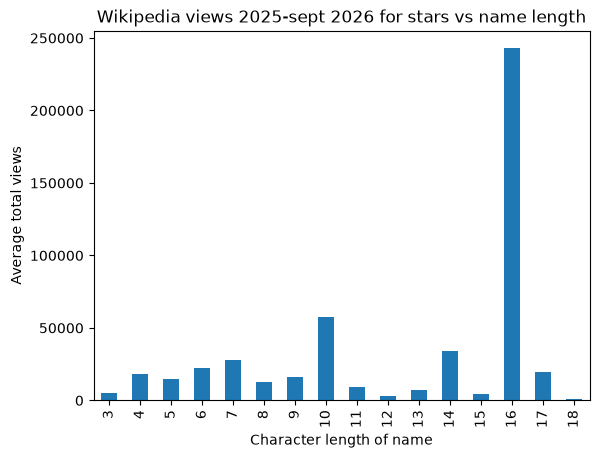

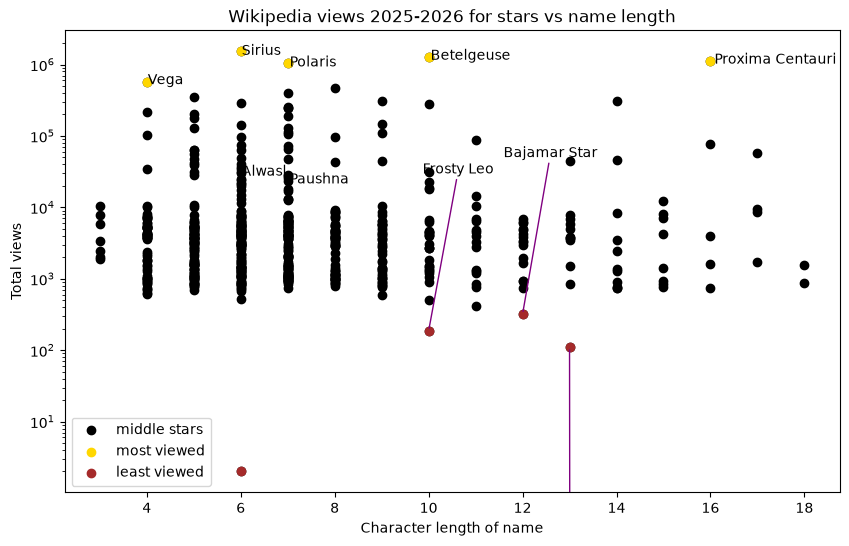

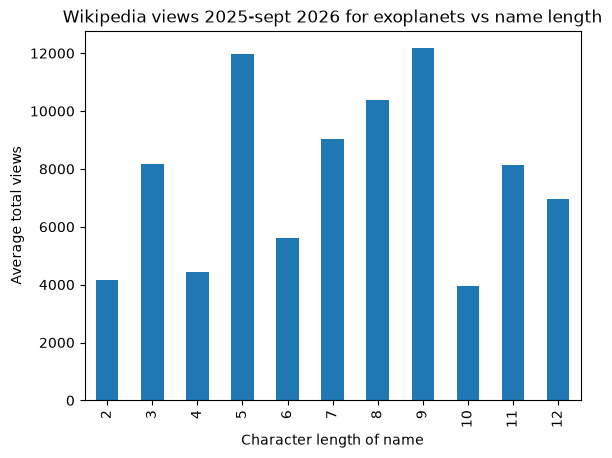

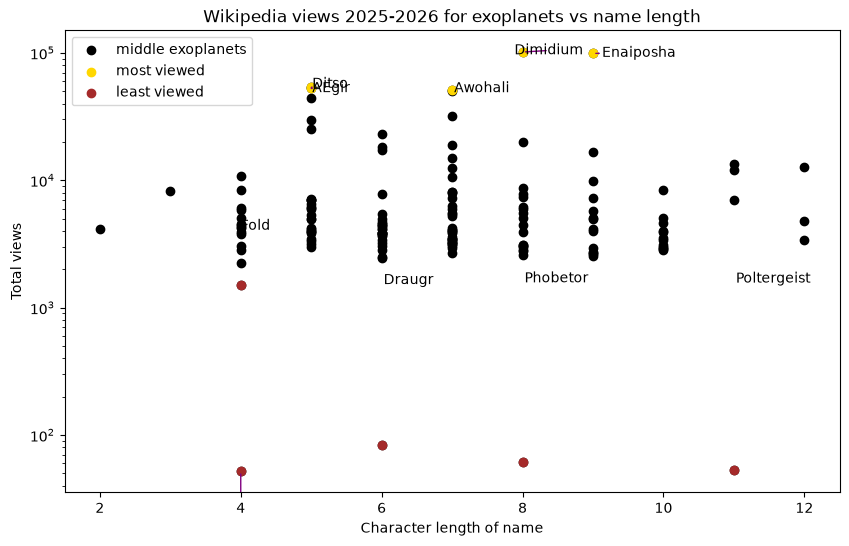

In [34]:
def plot_bar(df, label):
    df.groupby("name_length")["total_views"].mean().plot(kind="bar")
    plt.xlabel("Character length of name")
    plt.ylabel("Average total views")
    plt.title(f"Wikipedia views 2025-sept 2026 for {label} vs name length")
    plt.show()

def plot_scatter(df, label):
    top = df.nlargest(5, "total_views")
    bottom = df.nsmallest(5, "total_views")
    plt.figure(figsize=(10, 6))
    plt.scatter(df["name_length"], df["total_views"], color="black", label=f"middle {label}")
    plt.scatter(top["name_length"], top["total_views"], color="gold", label="most viewed")
    plt.scatter(bottom["name_length"], bottom["total_views"], color="brown", label="least viewed")
    labels = [plt.text(r["name_length"], r["total_views"], r["name_only"])
              for _, r in pd.concat([top, bottom]).iterrows()]
    adjust_text(labels, arrowprops=dict(arrowstyle="-", color="purple"))
    plt.xlabel("Character length of name")
    plt.ylabel("Total views")
    plt.yscale("log")
    plt.title(f"Wikipedia views 2025-2026 for {label} vs name length")
    plt.legend()
    plt.show()

for label, df in [("stars", stars), ("exoplanets", planets)]:
    plot_bar(df, label)
    plot_scatter(df, label)

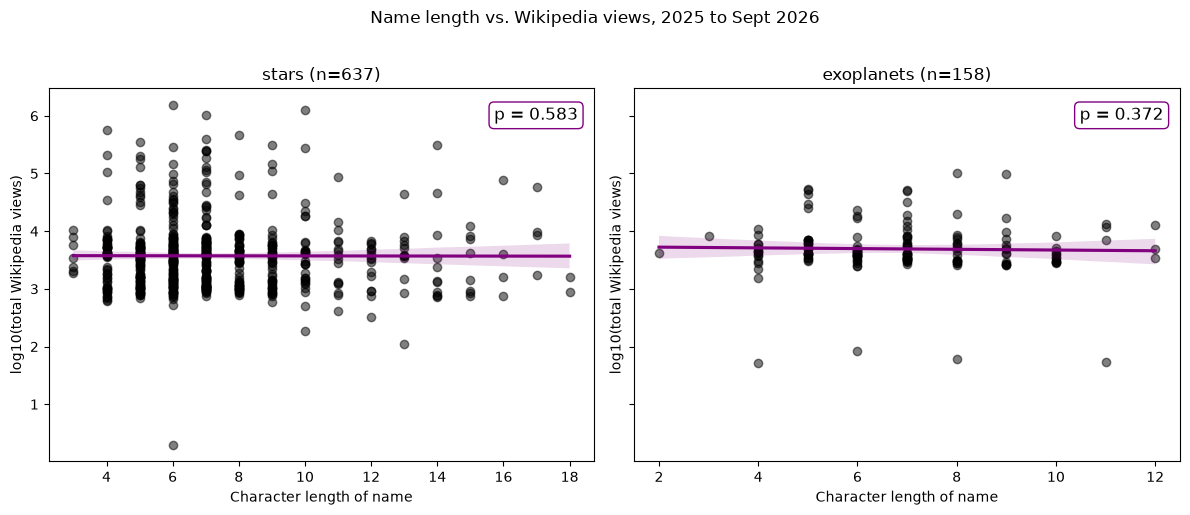

In [24]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

data = combined[combined["total_views"] > 0].copy()
data["log_views"] = np.log10(data["total_views"])

types = data["body_type"].unique()
fig, axes = plt.subplots(1, len(types), figsize=(6 * len(types), 5), sharey=True)
axes = np.atleast_1d(axes)

for ax, t in zip(axes, types):
    d = data[data["body_type"] == t]
    sns.regplot(data=d, x="name_length", y="log_views", ax=ax,
                scatter_kws={"alpha": 0.5, "color": "black"},
                line_kws={"color": "purple"})

    p = spearmanr(d["name_length"], d["total_views"])[1]
    p_text = "p < 0.001" if p < 0.001 else f"p = {p:.3f}"
    ax.text(0.97, 0.95, p_text, transform=ax.transAxes, ha="right", va="top",
            fontsize=12, bbox=dict(boxstyle="round", facecolor="white", edgecolor="purple"))

    ax.set_title(f"{t}s (n={len(d)})")
    ax.set_xlabel("Character length of name")
    ax.set_ylabel("log10(total Wikipedia views)")

plt.suptitle("Name length vs. Wikipedia views, 2025 to Sept 2026", y=1.02)
plt.tight_layout()
plt.show()

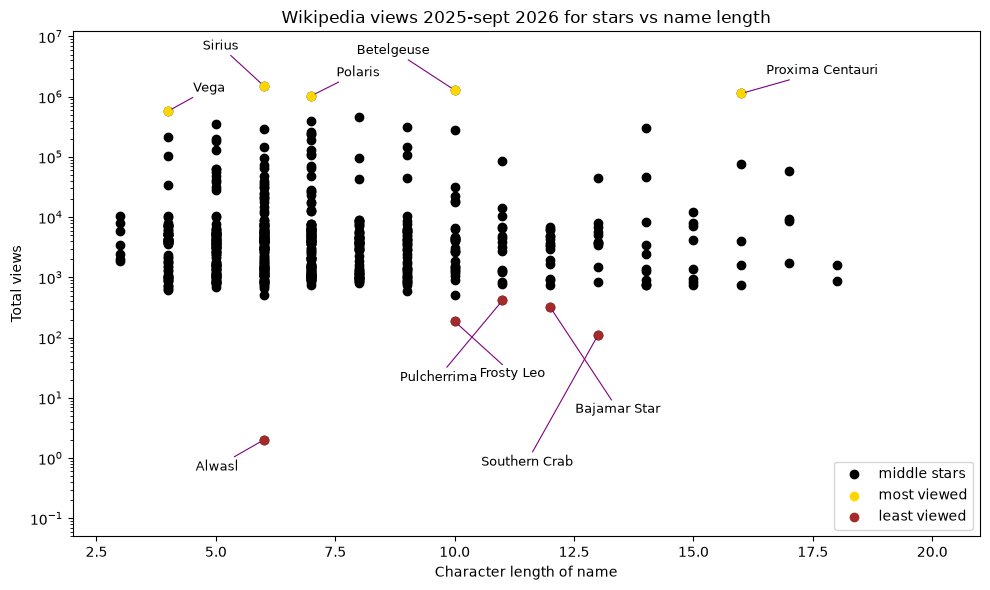

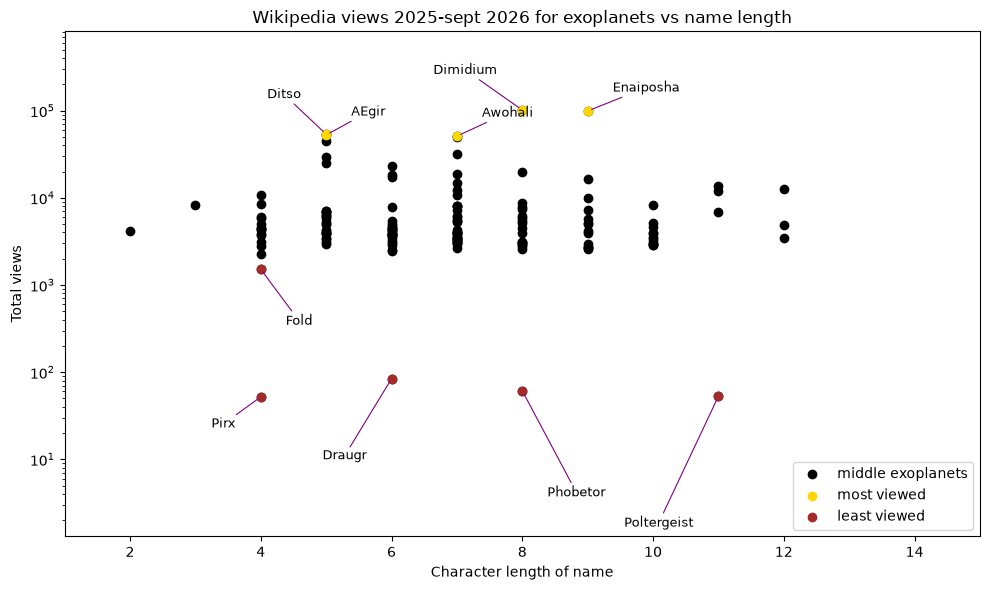

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def plot_scatter(df, label, n=5):
    df = df[df["total_views"] > 0]
    top = df.nlargest(n, "total_views")
    bottom = df.nsmallest(n, "total_views")

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.scatter(df["name_length"], df["total_views"], color="black", label=f"middle {label}")
    ax.scatter(top["name_length"], top["total_views"], color="gold", label="most viewed")
    ax.scatter(bottom["name_length"], bottom["total_views"], color="brown", label="least viewed")

    ax.set_yscale("log")
    ax.set_ylim(df["total_views"].min() / 40, df["total_views"].max() * 8)
    ax.set_xlim(df["name_length"].min() - 1, df["name_length"].max() + 3)

    arrow = dict(arrowstyle="-", color="purple", lw=0.8, shrinkA=0, shrinkB=3)

    # most viewed
    # most viewed: small, fixed offsets chosen per label
    for i, (_, r) in enumerate(top.sort_values("name_length").iterrows()):
        side = 1 if i % 2 == 0 else -1
        ax.annotate(r["name_only"], xy=(r["name_length"], r["total_views"]),
                    xytext=(side * 18, 14 + 12 * (i % 2)), textcoords="offset points",
                    ha="left" if side == 1 else "right", fontsize=9, arrowprops=arrow)

    # least viewed
    for i, (_, r) in enumerate(bottom.sort_values("name_length").iterrows()):
        side = -1 if i % 2 == 0 else 1
        ax.annotate(r["name_only"], xy=(r["name_length"], r["total_views"]),
                    xytext=(side * 18, -22 - 18 * i), textcoords="offset points",
                    ha="left" if side == 1 else "right", fontsize=9, arrowprops=arrow)

    ax.set_xlabel("Character length of name")
    ax.set_ylabel("Total views")
    ax.set_title(f"Wikipedia views 2025-sept 2026 for {label} vs name length")
    ax.legend(loc="lower right")
    plt.tight_layout()
    plt.show()

plot_scatter(stars, "stars")
plot_scatter(planets, "exoplanets")

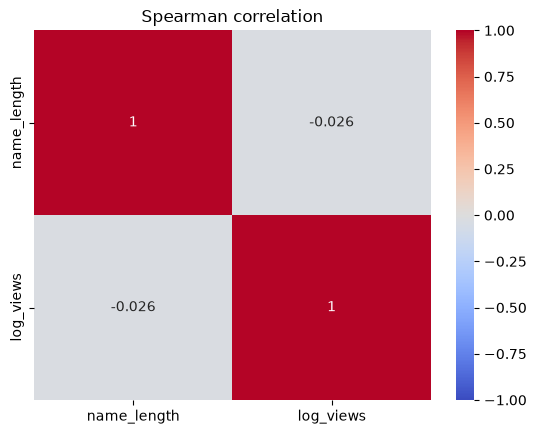

In [22]:

#single correlation matrix
corr = data[["name_length", "log_views"]].corr(method="spearman")
sns.heatmap(corr, annot=True, vmin=-1, vmax=1, cmap="coolwarm")
plt.title("Spearman correlation")
plt.show()